In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_9/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Пайплайн руками vs sktime (Peyton Manning)

Один и тот же прогноз бустингом построим двумя способами:

1. **руками** — pandas `shift`/`rolling` + `CatBoostRegressor`;
2. **в sktime** — `make_reduction` + `WindowSummarizer` + `DateTimeFeatures`.

Признаки одинаковые, поэтому прогнозы должны почти совпасть. Интересно другое: где в каждом
варианте легко ошибиться и сколько кода нужно, чтобы не ошибиться.

Данные — дневные просмотры страницы Пейтона Мэннинга в Википедии (уже в логарифме),
2007-12 … 2016-01. Горизонт H = 90 дней.

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import time  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from sktime.forecasting.compose import (  # noqa: E402
    ForecastingPipeline,
    TransformedTargetForecaster,
    make_reduction,
)
from sktime.forecasting.naive import NaiveForecaster  # noqa: E402
from sktime.split import temporal_train_test_split  # noqa: E402
from sktime.transformations.series.date import DateTimeFeatures  # noqa: E402
from sktime.transformations.series.impute import Imputer  # noqa: E402
from sktime.transformations.summarize import WindowSummarizer  # noqa: E402

from common import mae, plot_forecast  # noqa: E402

H = 90
LAGS = [90, 120, 150, 180]  # все лаги >= H: на любом шаге горизонта они известны
WINDOWS = [30, 90]  # скользящие средние, сдвинутые на H


def make_catboost():
    return CatBoostRegressor(iterations=800, learning_rate=0.05, depth=4, random_seed=0, verbose=False)

## 0. Постановка и пропуски дат

In [2]:
raw = common.load_peyton()
full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="D")
missing = full_index.difference(raw.index)
print(f"{len(raw)} наблюдений, {len(full_index)} дней в календаре, пропущено дат: {len(missing)}")
print("первые пропуски:", [d.date().isoformat() for d in missing[:5]])

2905 наблюдений, 2964 дней в календаре, пропущено дат: 59
первые пропуски: ['2008-01-31', '2008-02-28', '2008-03-01', '2008-03-03', '2008-03-04']


Пропущенные даты — не `NaN` в столбце, а **отсутствующие строки**. Это опасно для лагов:
`shift(90)` сдвигает на 90 **строк**, а не на 90 дней. После пропуска «лаг 90» молча
превращается в «лаг 91, 92, …».

In [3]:
naive_shift = raw.shift(90)
true_lag = raw.reindex(raw.index - pd.Timedelta(days=90)).set_axis(raw.index)
wrong = (naive_shift - true_lag).abs() > 0  # NaN (нет значения 90 дней назад) сюда не попадает
print(f"строк, где shift(90) взял не то значение: {wrong.sum()} из {len(raw)}")

строк, где shift(90) взял не то значение: 1304 из 2905


Поэтому первый шаг в обоих вариантах — регулярная сетка `asfreq("D")` и заполнение пропусков:
руками — `interpolate()`, в sktime — трансформация `Imputer`.

Ряд — многосезонный (неделя, год — сезон NFL), с всплесками в плей-офф.

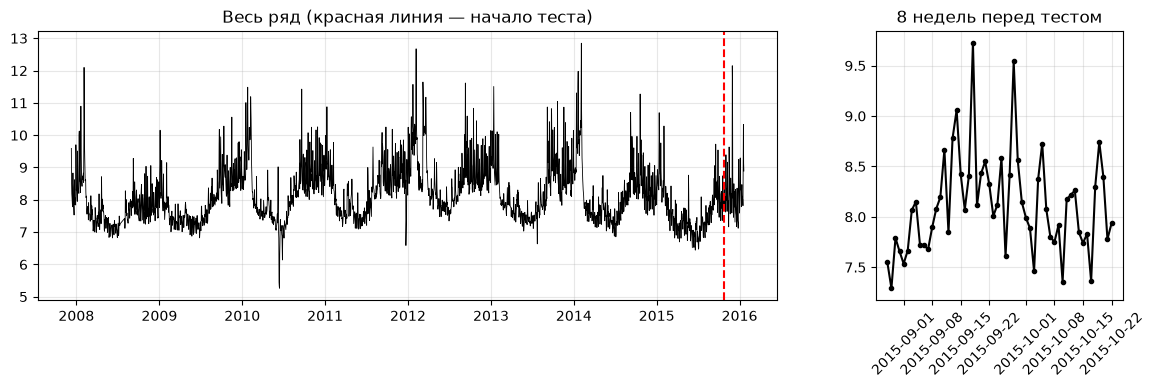

In [4]:
y = raw.asfreq("D").interpolate()
y_train, y_test = y.iloc[:-H], y.iloc[-H:]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(y.index, y, lw=0.6, color="black")
axes[0].axvline(y_test.index[0], color="red", ls="--")
axes[0].set_title("Весь ряд (красная линия — начало теста)")
week = y.iloc[-H - 56 : -H]
axes[1].plot(week.index, week, marker=".", color="black")
axes[1].set_title("8 недель перед тестом")
axes[1].tick_params(axis="x", rotation=45)
for ax in axes:
    ax.grid(alpha=0.3)

Бейзлайн — недельный наивный прогноз: «повторить последнюю неделю».

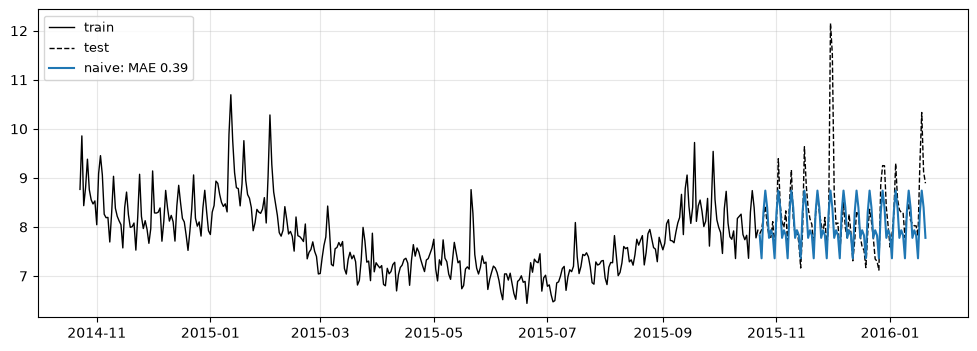

In [5]:
fh = np.arange(1, H + 1)
naive = NaiveForecaster(strategy="last", sp=7).fit(y_train, fh=fh).predict()
results = {"naive (последняя неделя)": {"MAE": mae(y_test, naive)}}
plot_forecast(y_train, y_test, {"naive": naive}, metric=mae, metric_name="MAE", last=365);

## 1. Руками: pandas + CatBoost

Признаки:
- лаги 90, 120, 150, 180 дней;
- скользящие средние за 30 и 90 дней, **сдвинутые на H**: `shift(H).rolling(w)`;
- календарь: день недели, месяц, день года.

Главное правило против утечки (лонгрид §2.4): **до** построения признаков заменить target
на тесте на `NaN`. Тогда любой признак, который случайно «подсмотрел» тест, окажется `NaN`,
и это сразу будет видно.

In [6]:
start = time.perf_counter()

df = pd.DataFrame({"y": y})
df.loc[y_test.index, "y"] = np.nan  # маскируем тест

for lag in LAGS:
    df[f"lag_{lag}"] = df["y"].shift(lag)
for w in WINDOWS:
    df[f"mean_{w}"] = df["y"].shift(H).rolling(w).mean()
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["day_of_year"] = df.index.dayofyear

features = [c for c in df.columns if c != "y"]
train = df.loc[y_train.index].dropna()  # первые 180 дней без лагов отбрасываем
manual_model = make_catboost().fit(train[features], train["y"])
manual = pd.Series(manual_model.predict(df.loc[y_test.index, features]), index=y_test.index)

time_manual = time.perf_counter() - start
print(f"NaN в признаках теста: {df.loc[y_test.index, features].isna().sum().sum()} — утечки нет")
print(f"MAE = {mae(y_test, manual):.3f}, {time_manual:.1f} с")
results["CatBoost руками"] = {"MAE": mae(y_test, manual)}

NaN в признаках теста: 0 — утечки нет
MAE = 0.485, 0.4 с


Посмотрим, как маска ловит ошибку. Типичная опечатка — сдвиг на один день меньше горизонта:
`shift(H - 1)`. На последнем дне теста такой признак берёт значение из первого дня теста,
то есть из будущего, — и благодаря маске там оказывается `NaN`.

In [7]:
leaky = df["y"].shift(H - 1).rolling(30).mean()
print(f"NaN в признаке с shift(H - 1) на тесте: {leaky.loc[y_test.index].isna().sum()}")

NaN в признаке с shift(H - 1) на тесте: 1


Без маски этот признак тихо подсмотрел бы истинное значение, и MAE на тесте был бы лучше
реального.

## 2. sktime: тот же пайплайн из готовых блоков

- `Imputer(method="linear")` — заполняет пропуски, как `interpolate()`;
- `DateTimeFeatures` — календарь из индекса (через пустую `X`: без неё признаки не строятся);
- `make_reduction(..., transformers=[WindowSummarizer(...)])` — лаги и окна из самого `y`.

Синтаксис `WindowSummarizer`: `"lag": [90, 120, …]` — лаги; для остальных функций окно
задаётся парой `[lag, window_length]`: `"mean": [[90, 30]]` — среднее за 30 дней,
заканчивающееся 90 дней назад. Это ровно `shift(90).rolling(30).mean()`.

`pooling="global"` обязателен: `make_reduction` с `transformers` работает только в этом режиме,
для одного ряда это ничего не меняет.

In [8]:
y_raw = raw.asfreq("D")  # пропуски остаются NaN — их заполнит Imputer внутри пайплайна
y_raw_train, _ = temporal_train_test_split(y_raw, test_size=H)
X = pd.DataFrame(index=y_raw.index)
X_train, X_test = X.loc[y_raw_train.index], X.loc[y_test.index]

start = time.perf_counter()
forecaster = TransformedTargetForecaster(
    [
        Imputer(method="linear"),
        ForecastingPipeline(
            [
                DateTimeFeatures(manual_selection=["day_of_week", "month_of_year", "day_of_year"]),
                make_reduction(
                    make_catboost(),
                    strategy="recursive",
                    window_length=None,
                    pooling="global",
                    transformers=[
                        WindowSummarizer(lag_feature={"lag": LAGS, "mean": [[H, w] for w in WINDOWS]}, n_jobs=1)
                    ],
                ),
            ]
        ),
    ]
)
forecaster.fit(y_raw_train, X=X_train, fh=fh)
sk = forecaster.predict(X=X_test)
time_sktime = time.perf_counter() - start

print(f"MAE = {mae(y_test, sk):.3f}, {time_sktime:.1f} с")
print(f"корреляция прогнозов руками и sktime: {np.corrcoef(manual, sk)[0, 1]:.3f}")
results["CatBoost sktime"] = {"MAE": mae(y_test, sk)}

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

MAE = 0.471, 1.6 с
корреляция прогнозов руками и sktime: 0.988


Стратегия `recursive` здесь формальность: модель учится на шаг вперёд и на прогнозе подставляет
свои прогнозы вместо неизвестных `y`. Но все лаги ≥ 90 = H, поэтому ни на одном шаге горизонта
собственные прогнозы в признаки не попадают — это тот же «прямой» прогноз одной моделью, что и
руками.

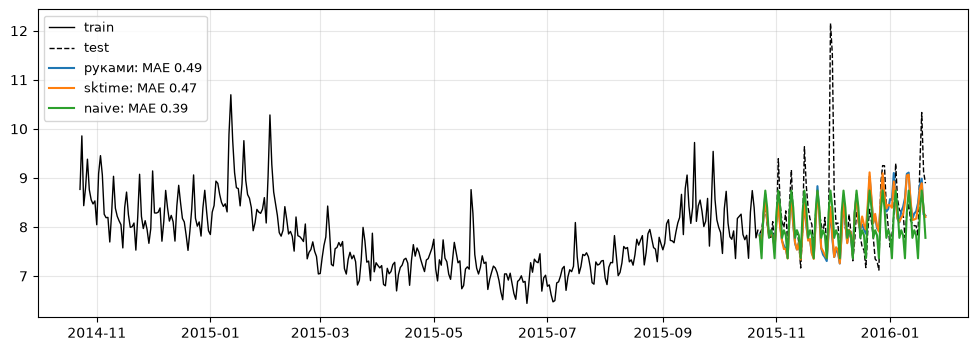

In [9]:
plot_forecast(y_train, y_test, {"руками": manual, "sktime": sk, "naive": naive}, metric=mae,
              metric_name="MAE", last=365);

## 3. Сравнение реализаций

| | руками | sktime |
|---|---|---|
| строк кода пайплайна | ~15 | ~15 |
| пропуски дат | `asfreq` + `interpolate` — легко забыть | `Imputer` — тоже надо не забыть, но он в пайплайне |
| утечка через окна | один неверный `shift` — и тест утёк | `[lag, window]` проверяется библиотекой |
| прогноз на новых данных | всю обработку повторить руками | `update` / `predict` того же объекта |
| бэктест | писать цикл самому | `evaluate` + сплиттер |
| прозрачность | видна каждая колонка | `WindowSummarizer` надо уметь читать |

По числу строк выигрыша нет. Выигрыш sktime — в том, что пайплайн — **один объект** с `fit/predict`:
его можно отдать в бэктест, подбор параметров или прод, и признаки на новых данных построятся так
же, как на train.

In [10]:
pd.DataFrame(results).T.round(3)

,MAE
naive (последняя неделя),0.394
CatBoost руками,0.485
CatBoost sktime,0.471


## 4. Честный вывод: бейзлайн обязателен

Обе реализации проигрывают недельному наивному прогнозу. Причина — в постановке: при H = 90 все
признаки из прошлого ряда старше 90 дней, **свежий уровень модель не видит**. А наивный прогноз
видит именно его — последнюю неделю.

Попробуем одно изменение, которое даёт модели свежий уровень: **прямая стратегия** (по модели на
каждый шаг горизонта). Модель для шага `h` обучается на последних 14 днях
перед прогнозом, поэтому для первых шагов свежие лаги доступны. 90 моделей — дорого, так что
уменьшим число деревьев до 200.

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

direct: MAE = 0.421, 13.2 с


,MAE
naive (последняя неделя),0.394
CatBoost руками,0.485
CatBoost sktime,0.471
"CatBoost direct, окно 14",0.421


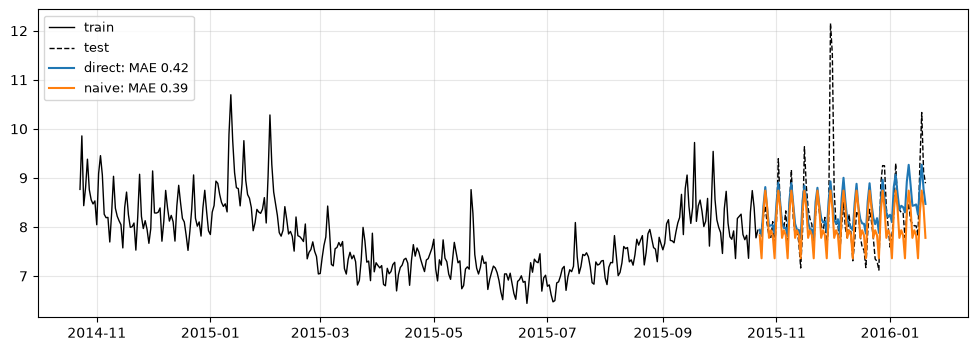

In [11]:
start = time.perf_counter()
direct = TransformedTargetForecaster(
    [
        Imputer(method="linear"),
        ForecastingPipeline(
            [
                DateTimeFeatures(manual_selection=["day_of_week", "month_of_year", "day_of_year"]),
                make_reduction(
                    CatBoostRegressor(iterations=200, learning_rate=0.05, depth=4, random_seed=0, verbose=False),
                    strategy="direct",
                    window_length=14,
                ),
            ]
        ),
    ]
)
direct.fit(y_raw_train, X=X_train, fh=fh)
direct_pred = direct.predict(X=X_test)
print(f"direct: MAE = {mae(y_test, direct_pred):.3f}, {time.perf_counter() - start:.1f} с")
results["CatBoost direct, окно 14"] = {"MAE": mae(y_test, direct_pred)}

plot_forecast(y_train, y_test, {"direct": direct_pred, "naive": naive}, metric=mae, metric_name="MAE", last=365)
pd.DataFrame(results).T.round(3)

Прямая стратегия заметно лучше, но наивный прогноз всё ещё не побеждён. Это нормальный
результат, а не провал:

1. **Реализации эквивалентны** — руками и в sktime получаются одни и те же прогнозы (корреляция
   ≈ 0.99); выбор — вопрос удобства и защиты от ошибок, а не качества.
2. **Бейзлайн обязателен**: без него «MAE 0.47» выглядит приемлемо, а на деле модель хуже, чем
   «повторить последнюю неделю».
3. **Длинный горизонт отнимает у модели свежую информацию**. Что с этим делать — выбирать
   стратегию прогнозирования (рекурсия, прямая, MIMO и их комбинации).